# Экзаменационная задача №03. Выбор ценовой стратегии для AI-сервиса по созданию контента

**Дисциплина:** Экономика информатизации, лекция №4
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №03: ВЫБОР ЦЕНОВОЙ СТРАТЕГИИ ДЛЯ AI-СЕРВИСА ПО СОЗДАНИЮ КОНТЕНТА
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №4)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Стартап «AI-Копирайтер» выпускает сервис, который пишет маркетинговые тексты. Нужно выбрать одну из четырёх ценовых
стратегий: Freemium, подписка, динамическая цена или персональная цена. У них разная цена, разная доля платящих
и разный отток (churn). От этого зависят ценность клиента (LTV) и то, окупается ли его привлечение.

**Цель:** выбрать стратегию, которая даёт проекту больше всего денег за 3 года, и проверить, насколько выбор надёжен.

**Что нужно сделать:** ARPU и LTV по стратегиям; LTV/CAC по каналам; прибыль и NPV за 3 года; чувствительность к конверсии,
оттоку и CAC (±30 %); выбор стратегии, план запуска, метрики и риски.

Тема лекции №4: у цифрового продукта почти нулевые затраты на копию, Freemium, подписка, динамическая и персональная цена
(ценовая дискриминация), юнит-экономика LTV/CAC.

## 2. Исходные данные

In [2]:
# 1.1. Рынок и параметры сервиса (из условия)
market = 500_000              # потенциальный рынок, пользователей
dev_cost = 15_000_000         # разработка (год 0), руб.
support_month = 2_000_000     # поддержание и облако, руб./мес.
channels = {"Реклама": 1_500, "Контент-маркетинг/SEO": 800, "Виральный рост": 100}   # CAC по каналам
r = 0.12; years = 3
base_users = {0: 1_000, 1: 2_000, 2: 3_000, 3: 3_600}   # +100%, +50%, +20% по годам

# 1.2. Стратегии ценообразования
strategies = pd.DataFrame({
    "Стратегия": ["Freemium", "Подписка", "Динамическая", "Персонализированная"],
    "Цена (ср. чек), руб./мес.": [2_000, 1_500, 1_250, 1_500],
    "Конверсия": [0.02, 0.20, 0.15, 0.12],
    "Churn в мес.": [0.08, 0.05, 0.06, 0.04],
}).set_index("Стратегия")
strategies

,"Цена (ср. чек), руб./мес.",Конверсия,Churn в мес.
Стратегия,,,
Freemium,2000,0.02,0.08
Подписка,1500,0.20,0.05
Динамическая,1250,0.15,0.06
Персонализированная,1500,0.12,0.04


**Допущения:**
- Средний чек динамической стратегии берём из середины диапазона 500–2 000 руб., то есть 1 250 руб. Для персональной 1 500 руб.:
  цены от 300 до 5 000 руб., но большинство клиентов малый бизнес, поэтому типичная цена ближе к нижней границе.
- Число зарегистрированных растёт по модели из условия. Платящие = база × конверсия.
- Основной канал привлечения **контент-маркетинг (CAC 800 руб.)**, он средний по цене. Расходы на привлечение =
  (прирост базы + замена ушедших платящих) × CAC.
- Годовой отток платящих $1-(1-churn)^{12}$. Разработка 15 млн руб. в году 0, выручка и затраты в конце каждого года.

## 3. Математическая модель

$$ARPU = Цена\cdot Конверсия,\qquad LTV=\frac{ARPU}{Churn},\qquad \frac{LTV}{CAC}\ \ (\text{норма} \ge 3)$$

Прибыль года $t$:
$$\Pi_t = 12\cdot ARPU\cdot N_t - 12\cdot C_{поддерж} - CAC\cdot\big[(N_t-N_{t-1}) + N_t\cdot conv\cdot(1-(1-churn)^{12})\big]$$

$$NPV = -C_{разраб} + \sum_{t=1}^{3}\frac{\Pi_t}{(1+r)^t}$$

Надёжность стратегии смотрим по тому, насколько меняется NPV, если конверсия, отток и CAC сдвигаются на ±30 %.

## 4. Реализация расчёта
### 4.1. ARPU, LTV и LTV/CAC

In [3]:
m = strategies.copy()
m["ARPU, руб./мес."] = m["Цена (ср. чек), руб./мес."] * m["Конверсия"]
m["Срок жизни, мес."] = 1 / m["Churn в мес."]
m["LTV, руб."] = m["ARPU, руб./мес."] / m["Churn в мес."]
m[["ARPU, руб./мес.", "Срок жизни, мес.", "LTV, руб."]]

,"ARPU, руб./мес.","Срок жизни, мес.","LTV, руб."
Стратегия,,,
Freemium,40.00,12.50,500.00
Подписка,300.00,20.00,6 000.00
Динамическая,187.50,16.67,3 125.00
Персонализированная,180.00,25.00,4 500.00


In [4]:
ltv_cac = pd.DataFrame({ch: m["LTV, руб."] / cac for ch, cac in channels.items()})
ltv_cac.columns = [f"{c} (CAC {v})" for c, v in channels.items()]
print("LTV/CAC (≥3 — здоровая юнит-экономика):")
ltv_cac.round(2)

LTV/CAC (≥3 — здоровая юнит-экономика):


,Реклама (CAC 1500),Контент-маркетинг/SEO (CAC 800),Виральный рост (CAC 100)
Стратегия,,,
Freemium,0.33,0.62,5.00
Подписка,4.00,7.50,60.00
Динамическая,2.08,3.91,31.25
Персонализированная,3.00,5.62,45.00


### 4.2. Прибыль и NPV за 3 года

In [5]:
def forecast(price, conv, churn, cac=channels["Контент-маркетинг/SEO"], users=base_users):
    """Годовой прогноз выручки, затрат и прибыли стратегии."""
    arpu = price * conv
    rows = [{"Год": 0, "База": users[0], "Платящие": users[0] * conv, "Выручка": 0.0,
             "Поддержка": 0.0, "Привлечение": 0.0, "Разработка": dev_cost}]
    for t in range(1, years + 1):
        n, n_prev = users[t], users[t - 1]
        churned_paying = n * conv * (1 - (1 - churn) ** 12)
        rows.append({"Год": t, "База": n, "Платящие": n * conv, "Выручка": 12 * arpu * n,
                     "Поддержка": 12 * support_month, "Привлечение": cac * ((n - n_prev) + churned_paying),
                     "Разработка": 0.0})
    df = pd.DataFrame(rows).set_index("Год")
    df["Прибыль"] = df["Выручка"] - df["Поддержка"] - df["Привлечение"] - df["Разработка"]
    return df

def strategy_npv(name, k_conv=1, k_churn=1, k_cac=1, users=base_users):
    s = strategies.loc[name]
    df = forecast(s.iloc[0], s.iloc[1] * k_conv, s.iloc[2] * k_churn, channels["Контент-маркетинг/SEO"] * k_cac, users)
    return npv(df["Прибыль"].values, r)

forecasts = {name: forecast(*strategies.loc[name].values) for name in strategies.index}
print("Пример — стратегия «Подписка», руб.:")
forecasts["Подписка"].round(0)

Пример — стратегия «Подписка», руб.:


,База,Платящие,Выручка,Поддержка,Привлечение,Разработка,Прибыль
Год,,,,,,,
0,1000,200.00,0.00,0.00,0.00,15 000 000.00,-15 000 000.00
1,2000,400.00,7 200 000.00,24 000 000.00,947 085.00,0.00,-17 747 085.00
2,3000,600.00,10 800 000.00,24 000 000.00,1 020 627.00,0.00,-14 220 627.00
3,3600,720.00,12 960 000.00,24 000 000.00,744 753.00,0.00,-11 784 753.00


In [6]:
summary = pd.DataFrame({
    "Выручка за 3 года, млн": {n: f["Выручка"].sum() / 1e6 for n, f in forecasts.items()},
    "Прибыль за 3 года, млн": {n: f["Прибыль"].sum() / 1e6 for n, f in forecasts.items()},
    "NPV (12%), млн": {n: npv(f["Прибыль"].values, r) / 1e6 for n, f in forecasts.items()},
})
# Сколько пользователей нужно, чтобы выручка покрыла поддержку платформы
summary["База для покрытия поддержки, чел."] = (support_month / m["ARPU, руб./мес."]).round(0)
summary["Доля рынка"] = summary["База для покрытия поддержки, чел."] / market
summary

,"Выручка за 3 года, млн","Прибыль за 3 года, млн","NPV (12%), млн","База для покрытия поддержки, чел.",Доля рынка
Freemium,4.13,-85.04,-71.17,50 000.00,0.10
Подписка,30.96,-58.75,-50.57,6 667.00,0.01
Динамическая,19.35,-70.27,-59.60,10 667.00,0.02
Персонализированная,18.58,-70.82,-60.03,11 111.00,0.02


По модели из условия к третьему году в сервисе всего 3 600 пользователей (0,7 % рынка). А чтобы окупить хотя бы
поддержку платформы, нужно от 6,7 тыс. (подписка) до 50 тыс. (Freemium). Поэтому в базовом прогнозе **все стратегии убыточны**,
и сравнивать их нужно по тому, у какой убыток меньше и какая быстрее выходит в плюс при росте.
Добавим сценарий побольше: тот же рост, но старт с 10 000 пользователей (2 % рынка). Это реально, если запускаться
с маркетинговым бюджетом.

In [7]:
scaled_users = {t: v * 10 for t, v in base_users.items()}
summary["NPV при базе ×10, млн"] = [strategy_npv(n, users=scaled_users) / 1e6 for n in strategies.index]
summary.round(2)

,"Выручка за 3 года, млн","Прибыль за 3 года, млн","NPV (12%), млн","База для покрытия поддержки, чел.",Доля рынка,"NPV при базе ×10, млн"
Freemium,4.13,-85.04,-71.17,50 000.00,0.10,-57.91
Подписка,30.96,-58.75,-50.57,6 667.00,0.01,148.09
Динамическая,19.35,-70.27,-59.60,10 667.00,0.02,57.82
Персонализированная,18.58,-70.82,-60.03,11 111.00,0.02,53.49


### 4.3. Анализ чувствительности (±30 %)

In [8]:
sens_rows = []
for name in strategies.index:
    base_npv = strategy_npv(name, users=scaled_users)
    for par, key in [("Конверсия", "k_conv"), ("Churn", "k_churn"), ("CAC", "k_cac")]:
        lo, hi = strategy_npv(name, **{key: 0.7}, users=scaled_users), strategy_npv(name, **{key: 1.3}, users=scaled_users)
        sens_rows.append({"Стратегия": name, "Параметр": par, "NPV −30%, млн": lo / 1e6, "NPV база, млн": base_npv / 1e6,
                          "NPV +30%, млн": hi / 1e6, "Размах, млн": abs(hi - lo) / 1e6})
sens = pd.DataFrame(sens_rows)
robust = sens.groupby("Стратегия").agg(**{"Суммарный размах NPV, млн": ("Размах, млн", "sum"),
                                          "Худший NPV, млн": ("NPV −30%, млн", "min")})
robust["Худший NPV, млн"] = [min(sens[sens["Стратегия"] == n][["NPV −30%, млн", "NPV +30%, млн"]].min()) for n in robust.index]
display(sens.round(2))
robust.round(2)

,Стратегия,Параметр,"NPV −30%, млн","NPV база, млн","NPV +30%, млн","Размах, млн"
0,Freemium,Конверсия,-67.41,-57.91,-48.41,19.00
1,Freemium,Churn,-57.77,-57.91,-58.02,0.25
2,Freemium,CAC,-52.63,-57.91,-63.20,10.57
3,Подписка,Конверсия,76.79,148.09,219.39,142.60
4,Подписка,Churn,149.30,148.09,147.08,2.22
5,Подписка,CAC,154.66,148.09,141.52,13.14
6,Динамическая,Конверсия,13.60,57.82,102.05,88.44
7,Динамическая,Churn,58.81,57.82,57.03,1.78
8,Динамическая,CAC,64.18,57.82,51.47,12.71
9,Персонализированная,Конверсия,10.57,53.49,96.41,85.84


,"Суммарный размах NPV, млн","Худший NPV, млн"
Стратегия,,
Freemium,29.82,-67.41
Динамическая,102.93,13.60
Персонализированная,98.70,10.57
Подписка,157.96,76.79


## 5. Визуализация результатов

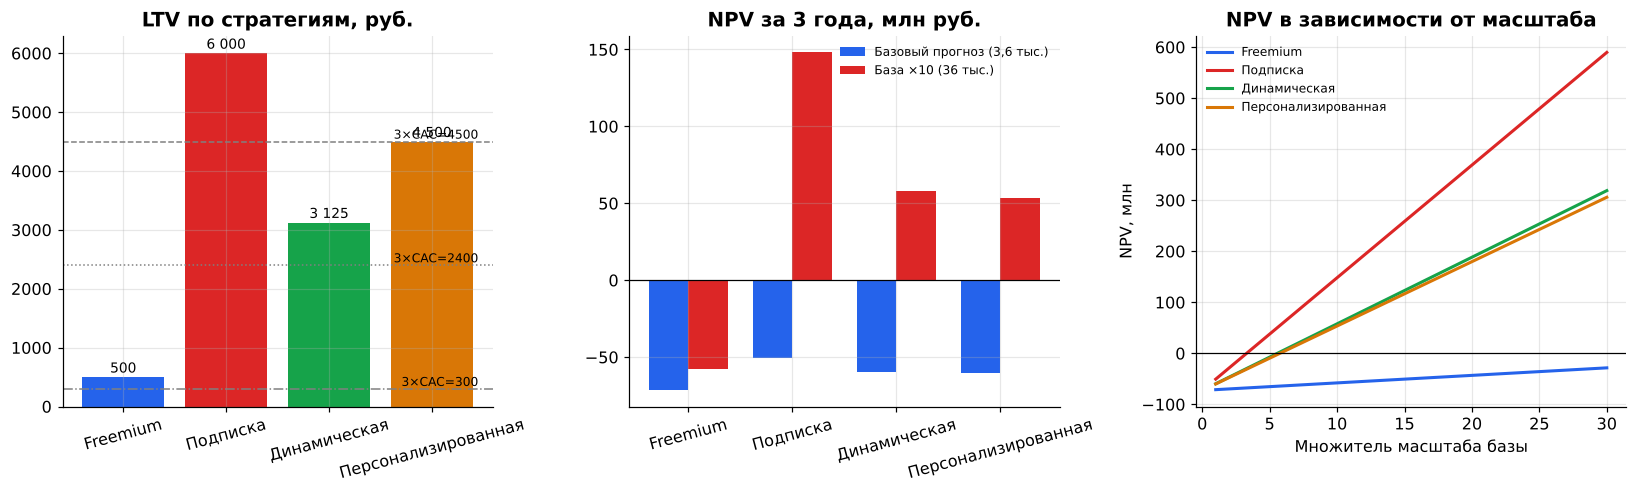

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axes[0]
bars = ax.bar(m.index, m["LTV, руб."], color=PALETTE[:4]); bar_labels(ax, bars, "{:,.0f}")
for cac, ls in zip(channels.values(), ["--", ":", "-."]):
    ax.axhline(3 * cac, ls=ls, color="gray", lw=1)
    ax.text(3.45, 3 * cac, f"3×CAC={3*cac}", fontsize=8, va="bottom", ha="right")
ax.set_title("LTV по стратегиям, руб."); ax.tick_params(axis="x", rotation=15)
ax = axes[1]
x = np.arange(4); w = 0.38
b1 = ax.bar(x - w/2, summary["NPV (12%), млн"], w, label="Базовый прогноз (3,6 тыс.)")
b2 = ax.bar(x + w/2, summary["NPV при базе ×10, млн"], w, label="База ×10 (36 тыс.)")
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(x, m.index, rotation=15)
ax.set_title("NPV за 3 года, млн руб."); ax.legend(fontsize=8)
ax = axes[2]
for name in strategies.index:
    sc = np.linspace(1, 30, 60)
    ax.plot(sc, [strategy_npv(name, users={t: v * s for t, v in base_users.items()}) / 1e6 for s in sc], lw=2, label=name)
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Множитель масштаба базы"); ax.set_ylabel("NPV, млн")
ax.set_title("NPV в зависимости от масштаба"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

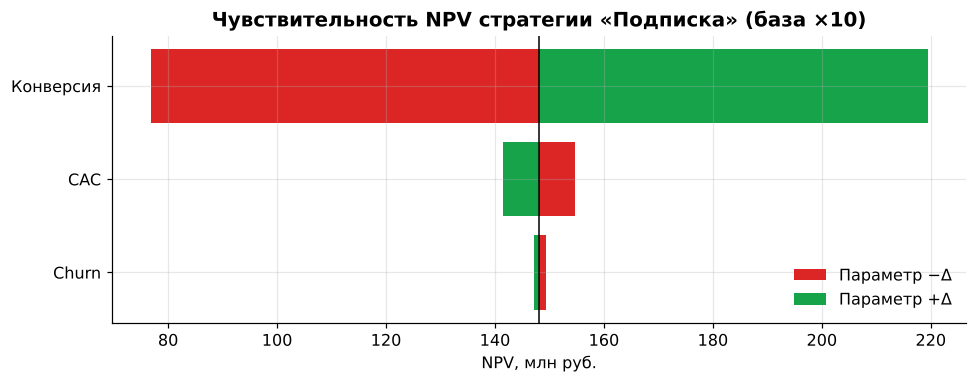

In [10]:
best = summary["NPV при базе ×10, млн"].idxmax()
s = sens[sens["Стратегия"] == best]
fig, ax = plt.subplots(figsize=(9, 3.6))
tornado(ax, list(s["Параметр"]), s["NPV −30%, млн"], s["NPV +30%, млн"], s["NPV база, млн"].iloc[0],
        f"Чувствительность NPV стратегии «{best}» (база ×10)", "NPV, млн руб.")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **ARPU и LTV.** У подписки самые высокие ARPU (300 руб. в месяц) и LTV (6 000 руб.). На втором месте персональная цена
  (LTV около 4 500 руб.), потому что у неё самый низкий отток. Хуже всех Freemium (ARPU 40 руб., LTV 500 руб.):
  высокая цена премиума не спасает при конверсии 2 %.
- **LTV/CAC.** Через рекламу (CAC 1 500 руб.) норму 3 и выше даёт только подписка (4,0), персональная цена на грани (3,0).
  Через контент-маркетинг проходят подписка (7,5), персональная (5,6) и динамическая (3,9). Freemium окупается только при
  виральном росте. Виральный канал лучший для любой стратегии.
- **NPV.** В базовом прогнозе (до 3 600 пользователей) убыточны все: постоянные расходы 24 млн руб. в год не покрываются.
  Меньше всего убыток у подписки. В сценарии ×10 подписка единственная выходит в плюс, и ей для этого нужно меньше пользователей,
  чем остальным.
- **Надёжность.** Сильнее всего NPV подписки зависит от конверсии (поэтому важен пробный период), меньше от оттока и CAC.
  Даже если любой параметр ухудшится на 30 %, NPV подписки всё равно лучше базового NPV других стратегий.

## 7. Выводы и рекомендации

**Выбор: подписка с пробным периодом, 1 500 руб. в месяц.** Самые высокие ARPU и LTV, LTV/CAC не ниже 3 даже в дорогом канале,
лучший NPV и самый большой запас прочности. Главное условие успеха это масштаб: только чтобы окупить поддержку, нужно
около 6,7 тыс. платящих (1,3 % рынка). Рост «с 1 000 пользователей» нужно ускорять.

**План запуска**
| Этап | Что делаем | Как продвигаем |
|---|---|---|
| Год 1, выход | подписка + 14 дней бесплатно, интеграции с Tilda, WordPress, VK | контент-маркетинг (кейсы, тексты «до и после»), SEO |
| Год 2, рост | реферальная программа (CAC 100–300 руб.), тарифы для агентств | партнёрства с курсами SMM, сообщества маркетологов |
| Год 3, зрелость | годовые тарифы со скидкой (меньше отток), персонализация для B2B | кейсы клиентов с цифрами, вебинары |

**Что отслеживать:** конверсия из пробного периода в оплату (от 20 %, каждую неделю), отток (меньше 5 % в месяц),
LTV/CAC по каналам (больше 3, каждый месяц), MRR и его рост, срок окупаемости CAC (меньше 6 месяцев), NRR (больше 100 %).

**Риски и что с ними делать**
| Риск | Что делать |
|---|---|
| Мало кто платит после пробного периода | A/B-тесты длины пробного периода, онбординг, лимит бесплатных генераций |
| Реклама дорожает | переносить бюджет в контент и рефералы |
| Конкуренты и бесплатные нейросети | узкая специализация (SEO, шаблоны под отрасли), качество, интеграции |
| Дорожают токены и облако | кеширование, выбор более дешёвых моделей (см. задачу про токены) |
| Мало пользователей | деньги давать по этапам: следующий раунд только при 3 000 платящих и LTV/CAC больше 3 |